# ⛰️ Lesson 04 · Gradient Descent & Backpropagation

*“Backpropagation is just the chain rule, applied patiently, from the answer back to the cause.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~120 min | 🟡 Intermediate | Day 3–4 | Lessons 01–03; high-school calculus (derivatives) |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Explain a **gradient** as 'which way is uphill, and how steeply?'
- Implement **gradient descent** and diagnose learning rates that are too small or too large
- Apply the **chain rule** by hand on a computational graph
- Derive and implement **backpropagation** for a multi-layer network in pure NumPy and train it
- Verify gradients with **numerical gradient checking**: the debugger of last resort
- Build a tiny **automatic-differentiation engine** (like a 60-line PyTorch autograd) and understand what `loss.backward()` does

## 🗺 Roadmap
1. Descending a foggy mountain
2. Gradient descent in 1-D (and the learning-rate Goldilocks zone)
3. Gradient descent for a real model
4. The chain rule: a worked example
5. Backpropagation for a full network
6. Training it from scratch on spirals
7. Gradient checking
8. Build your own autograd
9. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl

dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## 🌫 1. Descending a foggy mountain

You're hiking in thick fog and want the valley floor. You can't see far, but you can feel the **slope under your feet**.
The sensible strategy: *take a step in the steepest downhill direction, then re-feel the slope, then repeat.*

That's **gradient descent**. In maths:

* The **loss** $L(w)$ is the altitude at position $w$.
* The **gradient** $\nabla L$ points *uphill*; its length says how steep.
* So we step *against* it: $\;\boxed{w \leftarrow w - \eta\,\nabla L(w)}\;$ where $\eta$ (eta) is the **learning rate**: the step size.

A **derivative** answers: *"if I nudge $w$ a tiny bit, how much does the loss change?"* Let's feel one numerically:

In [2]:
f = lambda w: (w - 3) ** 2 + 1                       # a simple valley with its floor at w = 3
w, h = 5.0, 1e-5
numeric = (f(w + h) - f(w - h)) / (2 * h)            # "central difference": nudge both ways
analytic = 2 * (w - 3)                               # calculus: d/dw (w-3)² = 2(w-3)
print(f"slope at w=5 → numeric {numeric:.4f}, analytic {analytic:.4f}  (positive = uphill to the right → go LEFT)")

slope at w=5 → numeric 4.0000, analytic 4.0000  (positive = uphill to the right → go LEFT)


---
## 🎚 2. Gradient descent in one dimension: the Goldilocks learning rate

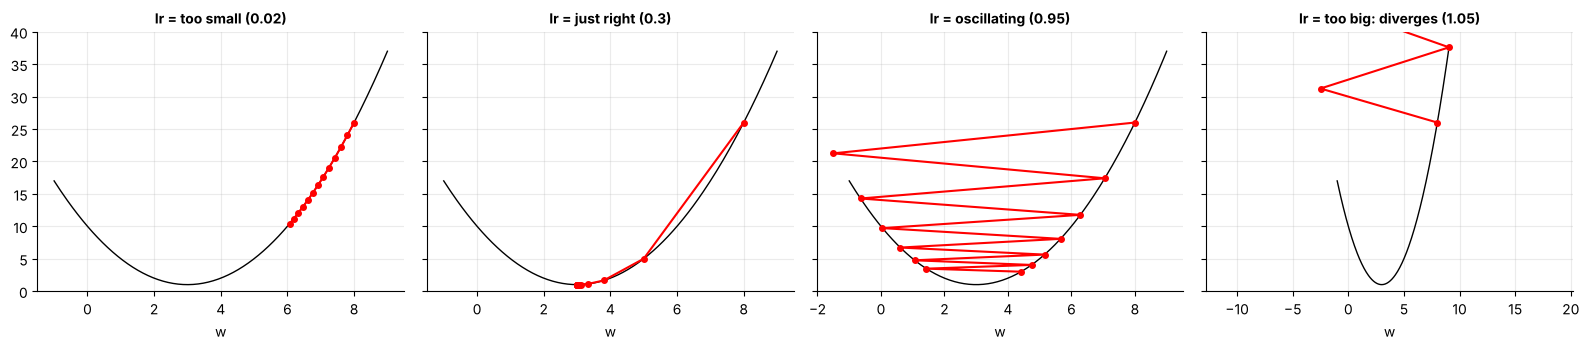

In [3]:
def gradient_descent_1d(grad, w0, lr, steps):
    w, path = w0, [w0]
    for _ in range(steps):
        w = w - lr * grad(w)             # THE update rule
        path.append(w)
    return np.array(path)

grad = lambda w: 2 * (w - 3)
ws = np.linspace(-1, 9, 200)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, lr, title in zip(axes, [0.02, 0.3, 0.95, 1.05], ["too small (0.02)", "just right (0.3)", "oscillating (0.95)", "too big: diverges (1.05)"]):
    path = gradient_descent_1d(grad, 8.0, lr, 12)
    ax.plot(ws, f(ws), "k-", lw=1); ax.plot(path, f(path), "ro-", ms=4)
    ax.set_title(f"lr = {title}", fontsize=10); ax.set_ylim(0, 40); ax.set_xlabel("w")
plt.tight_layout(); plt.show()

* **Too small** → safe but painfully slow.
* **Just right** → glides to the bottom.
* **Too big** → overshoots the valley, bounces from side to side, and for $\eta > 1$ on this bowl each step lands *farther up* the other wall: **divergence** (loss → ∞ / `nan`).

> 🛠 **Pro tip.** The learning rate is the single most important hyperparameter. If your loss explodes or turns `nan`, lower it by 10×. If it crawls, raise it by 3×. Lesson 06 shows systematic ways to choose it.

---
## 📉 3. Gradient descent on a real model: linear regression

Model $\hat y = wx+b$, loss $L=\frac1m\sum(\hat y_i-y_i)^2$. Differentiating:

$$\frac{\partial L}{\partial w}=\frac2m\sum(\hat y_i-y_i)\,x_i \qquad \frac{\partial L}{\partial b}=\frac2m\sum(\hat y_i-y_i)$$

Read it intuitively: *if predictions are too high where $x$ is positive, decrease $w$.* Let's watch gradient descent find the line.

gradient descent: w=2.052, b=1.007   (true 2, 1)
closed-form least squares: w=2.052, b=1.008


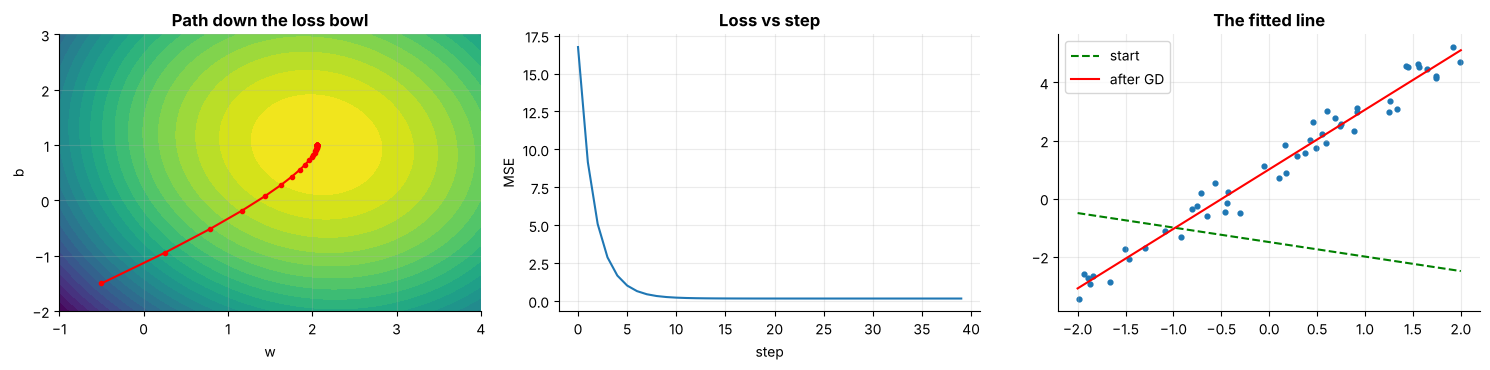

In [4]:
rng = np.random.default_rng(0)
x = rng.uniform(-2, 2, 50); y = 2.0 * x + 1.0 + rng.normal(0, 0.4, 50)          # truth: w=2, b=1

w, b, lr = -0.5, -1.5, 0.1
path, losses = [(w, b)], []
for step in range(40):
    y_hat = w * x + b
    losses.append(np.mean((y_hat - y) ** 2))
    dw = 2 * np.mean((y_hat - y) * x)
    db = 2 * np.mean(y_hat - y)
    w, b = w - lr * dw, b - lr * db
    path.append((w, b))
print(f"gradient descent: w={w:.3f}, b={b:.3f}   (true 2, 1)")
w_ls, b_ls = np.polyfit(x, y, 1); print(f"closed-form least squares: w={w_ls:.3f}, b={b_ls:.3f}")

ws_, bs_ = np.meshgrid(np.linspace(-1, 4, 100), np.linspace(-2, 3, 100))
loss = ((ws_[..., None] * x + bs_[..., None] - y) ** 2).mean(-1)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].contourf(ws_, bs_, loss, 25, cmap="viridis_r"); P = np.array(path); ax[0].plot(P[:, 0], P[:, 1], "r.-"); ax[0].set(title="Path down the loss bowl", xlabel="w", ylabel="b")
ax[1].plot(losses); ax[1].set(title="Loss vs step", xlabel="step", ylabel="MSE")
ax[2].scatter(x, y, s=12); xx = np.array([-2, 2]); ax[2].plot(xx, P[0, 0] * xx + P[0, 1], "g--", label="start"); ax[2].plot(xx, w * xx + b, "r", label="after GD"); ax[2].legend(); ax[2].set(title="The fitted line")
plt.tight_layout(); plt.show()

> 📝 **Note**: For linear regression an exact formula exists, so we don't *need* gradient descent. For neural networks **no closed form exists**: gradient descent is the only game in town. Linear regression is our safe playground.

---
## ⛓ 4. The chain rule: a worked example

A network is a long **chain of simple functions**, so its derivative is a **chain of simple derivatives multiplied together**:

$$\text{if } L = f(g(h(w))),\quad \frac{dL}{dw}=\frac{dL}{df}\cdot\frac{df}{dg}\cdot\frac{dg}{dh}\cdot\frac{dh}{dw}$$

**Analogy 🌽.** A farmer's profit depends on the price, which depends on the harvest size, which depends on rainfall. *How sensitive is profit to rainfall?* Multiply the sensitivities along the chain: (profit per price change) × (price change per harvest change) × (harvest change per rainfall change).

### Worked example: one neuron, one example
Neuron: $z=wx+b,\ a=\sigma(z),\ L=(a-y)^2$ with $x=1.5,\ y=1,\ w=0.8,\ b=0.1$.

**Forward pass** (always first: we need the numbers):
* $z = 0.8(1.5)+0.1 = 1.3$
* $a = \sigma(1.3) = 0.7858$
* $L = (0.7858-1)^2 = 0.0459$

**Backward pass**: walk the chain from $L$ back to $w$:

| Link | Derivative | Value |
|:--|:--|--:|
| $\partial L/\partial a$ | $2(a-y)$ | $2(0.7858-1) = -0.4284$ |
| $\partial a/\partial z$ | $\sigma'(z)=a(1-a)$ | $0.7858\times0.2142 = 0.1683$ |
| $\partial z/\partial w$ | $x$ | $1.5$ |
| $\partial z/\partial b$ | $1$ | $1$ |

So $\dfrac{\partial L}{\partial w}=(-0.4284)(0.1683)(1.5)\approx\mathbf{-0.1081}$ and $\dfrac{\partial L}{\partial b}=(-0.4284)(0.1683)(1)\approx\mathbf{-0.0721}$.

Both negative: *increasing $w$ or $b$ would decrease the loss* (the neuron's output 0.79 is below the target 1, so it wants to fire harder). Check with a numerical nudge:

In [5]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
x, y = 1.5, 1.0
def L_of(w, b): return (sigmoid(w * x + b) - y) ** 2

w, b = 0.8, 0.1
a = sigmoid(w * x + b)
dL_da, da_dz = 2 * (a - y), a * (1 - a)
print("by chain rule: dL/dw =", round(dL_da * da_dz * x, 4), "  dL/db =", round(dL_da * da_dz, 4))

h = 1e-6
print("by nudging   : dL/dw =", round((L_of(w + h, b) - L_of(w - h, b)) / (2 * h), 4),
      "  dL/db =", round((L_of(w, b + h) - L_of(w, b - h)) / (2 * h), 4))

by chain rule: dL/dw = -0.1081   dL/db = -0.0721
by nudging   : dL/dw = -0.1081   dL/db = -0.0721


---
## 🔁 5. Backpropagation for a full network

**Backpropagation** is *nothing more* than the chain rule applied efficiently to a layered network. Its trick: compute the forward pass once and **cache** each layer's values; then sweep **backward**, reusing each layer's gradient to get the previous one's.

Define $\delta^{[l]}=\partial L/\partial Z^{[l]}$ (the "error signal" at layer $l$). For a network with ReLU hidden layers and softmax + cross-entropy output over a batch of $m$ examples:

| Step | Formula | Meaning |
|:--|:--|:--|
| Output error | $\delta^{[L]}=\dfrac{1}{m}(\hat P - Y_{\text{one-hot}})$ | Prediction minus truth: *beautifully simple* |
| Weight gradient | $\dfrac{\partial L}{\partial W^{[l]}}=A^{[l-1]\,T}\,\delta^{[l]}$ | "Blame each weight by how much its input was active" |
| Bias gradient | $\dfrac{\partial L}{\partial b^{[l]}}=\sum_{\text{batch}}\delta^{[l]}$ | |
| Pass error back | $\delta^{[l-1]}=\big(\delta^{[l]}W^{[l]\,T}\big)\odot f'(Z^{[l-1]})$ | Distribute blame to the previous layer, gated by the activation's slope |

> 💡 **Big idea.** Each layer receives *how much the final loss cares about its output* from the layer above, multiplies by its own local slope, and hands the result to the layer below. **Every layer only needs local information**: which is why this scales to hundreds of layers.

Notice $f'(Z)$ for ReLU is 1 or 0: a neuron that was "off" in the forward pass passes **no blame** backwards. And here's the vanishing-gradient story from Lesson 02 in action: for sigmoids, $f'\le0.25$ gets multiplied in at *every* layer.

Let's implement it: the whole thing is ~30 lines:

In [6]:
class MLP:
    """A fully-connected network in plain NumPy: ReLU hidden layers, softmax + cross-entropy output."""
    def __init__(self, sizes, seed=0):
        rng = np.random.default_rng(seed)
        self.W = [rng.normal(0, np.sqrt(2 / a), (a, b)) for a, b in zip(sizes[:-1], sizes[1:])]   # He init
        self.b = [np.zeros(b) for b in sizes[1:]]

    def forward(self, X):
        self.acts, self.zs = [X], []                  # cache everything backprop will need
        A = X
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            Z = A @ W + b
            A = np.maximum(0, Z) if i < len(self.W) - 1 else Z       # last layer: raw logits
            self.zs.append(Z); self.acts.append(A)
        return A

    def loss_and_grads(self, X, y):
        logits = self.forward(X)
        m = len(y)
        e = np.exp(logits - logits.max(1, keepdims=True))
        probs = e / e.sum(1, keepdims=True)
        loss = -np.mean(np.log(probs[np.arange(m), y] + 1e-12))

        dZ = probs.copy(); dZ[np.arange(m), y] -= 1; dZ /= m          # softmax+CE gradient: (p - onehot)/m
        dW, db = [None] * len(self.W), [None] * len(self.W)
        for i in reversed(range(len(self.W))):
            dW[i] = self.acts[i].T @ dZ                                # gradient for this layer's weights
            db[i] = dZ.sum(0)
            if i > 0:
                dA_prev = dZ @ self.W[i].T                             # pass the error backwards...
                dZ = dA_prev * (self.zs[i - 1] > 0)                    # ...through the ReLU
        return loss, dW, db

    def predict(self, X):
        return self.forward(X).argmax(1)

---
## 🌀 6. Training it from scratch on a spiral

A spiral with three arms is a classic test: **no straight line (or single neuron) can separate it**, but a small network with hidden layers can.

epoch    0  loss 1.2530  accuracy 50.3%
epoch  400  loss 0.0405  accuracy 98.3%


epoch  800  loss 0.0285  accuracy 98.7%


epoch 1200  loss 0.0294  accuracy 99.0%


epoch 1600  loss 0.0251  accuracy 99.0%


epoch 2000  loss 0.0257  accuracy 99.0%


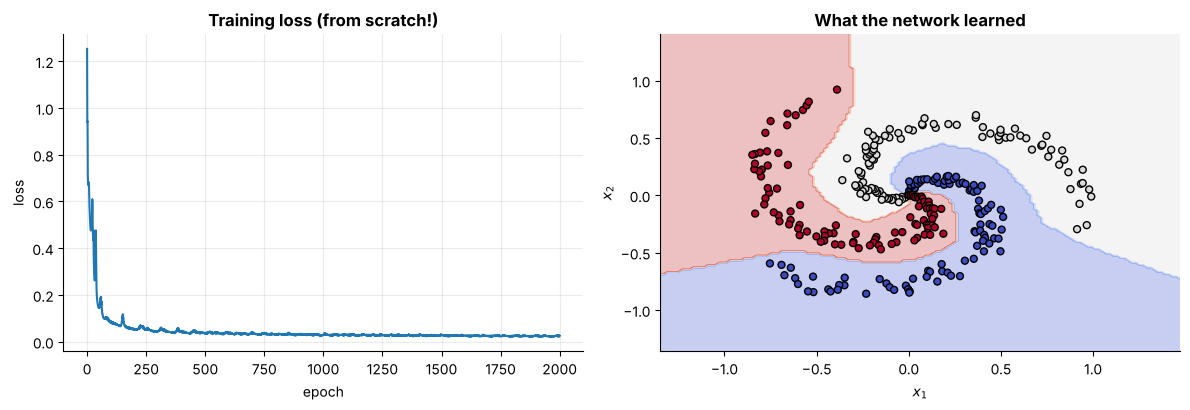

In [7]:
def make_spiral(n=100, k=3, noise=0.2, seed=0):
    rng = np.random.default_rng(seed)
    X, y = np.zeros((n * k, 2)), np.zeros(n * k, dtype=int)
    for j in range(k):
        ix = slice(n * j, n * (j + 1))
        r = np.linspace(0.0, 1, n)
        t = np.linspace(j * 4, (j + 1) * 4, n) + rng.normal(0, noise, n)
        X[ix], y[ix] = np.c_[r * np.sin(t), r * np.cos(t)], j
    return X, y

X, y = make_spiral()
net = MLP([2, 64, 64, 3], seed=1)
lr, history = 1.0, []
for epoch in range(2001):
    loss, dW, db = net.loss_and_grads(X, y)
    for i in range(len(net.W)):                       # gradient-descent update for every layer
        net.W[i] -= lr * dW[i]
        net.b[i] -= lr * db[i]
    history.append(loss)
    if epoch % 400 == 0:
        print(f"epoch {epoch:4d}  loss {loss:.4f}  accuracy {(net.predict(X) == y).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(history); ax[0].set(xlabel="epoch", ylabel="loss", title="Training loss (from scratch!)")
dl.plot_decision_boundary(net.predict, X, y, ax=ax[1], h=0.02, title="What the network learned")
plt.tight_layout(); plt.show()

> 💡 **Big idea**: You just trained a neural network **with no deep-learning library**. Everything PyTorch does (layers, losses, optimisers) is this loop, generalised, optimised and automated. If you understand this cell, you understand deep learning.

> 🧪 **Try it yourself**: Change the learning rate to 0.01 and 10; change the hidden sizes to `[2, 4, 3]`; change `2001` epochs to `200`. For each: *predict* what the boundary will look like first, then run.

---
## 🔍 7. Gradient checking: the debugger of last resort

Backprop code is easy to get subtly wrong (a transposed matrix, a missing `/m`). The fix: compare **analytic** gradients (your backprop) with **numerical** ones (nudge each weight, see how the loss changes). They should agree to ~7 decimal places:
$$\text{relative error}=\frac{\|g_{\text{analytic}}-g_{\text{numeric}}\|}{\|g_{\text{analytic}}\|+\|g_{\text{numeric}}\|}$$
(computed over a random sample of weights). Below **1e-5** is a pass; above **1e-3** means a bug.

In [8]:
def gradient_check(net, X, y, eps=1e-6, n_checks=8, seed=0):
    rng = np.random.default_rng(seed)
    _, dW, db = net.loss_and_grads(X, y)
    numeric, analytic = [], []
    for params, grads in [(net.W, dW), (net.b, db)]:
        for P, G in zip(params, grads):
            for _ in range(n_checks):                          # sample a few random weights per layer
                idx = tuple(rng.integers(0, s) for s in P.shape)
                old = P[idx]
                P[idx] = old + eps; lp, *_ = net.loss_and_grads(X, y)
                P[idx] = old - eps; lm, *_ = net.loss_and_grads(X, y)
                P[idx] = old                                   # ALWAYS restore the weight
                numeric.append((lp - lm) / (2 * eps)); analytic.append(G[idx])
    numeric, analytic = np.array(numeric), np.array(analytic)
    return np.linalg.norm(numeric - analytic) / (np.linalg.norm(numeric) + np.linalg.norm(analytic) + 1e-12)

rng = np.random.default_rng(5)
Xc, yc = rng.normal(size=(30, 2)), rng.integers(0, 3, 30)         # generic random data (see warning below)
small = MLP([2, 5, 4, 3], seed=2)
err = gradient_check(small, Xc, yc)
print(f"relative error: {err:.2e}  →", "backprop is correct ✅" if err < 1e-5 else "BUG 🐛")

relative error: 2.96e-10  → backprop is correct ✅


> ⚠️ **Watch out**: Why random data instead of our spiral? Spiral points at the origin give pre-activations of *exactly* 0: right on ReLU's kink, where the derivative is undefined and numerical differentiation disagrees with the formula. (We discovered this while writing this very lesson!) Gradient checks should use generic inputs, and a *tiny* disagreement at a kink is not a bug.

---
## 🤖 8. Build your own autograd (what `loss.backward()` really does)

Writing backprop by hand for every architecture would be tedious. Frameworks avoid it with **automatic differentiation**: every arithmetic operation *remembers how to compute its own local derivative*, and `backward()` chains them. Below is a **~60-line engine** in the spirit of Andrej Karpathy's *micrograd*. Read the `_backward` closures: each one is a single line of calculus from your textbook.

In [9]:
class Value:
    """A number that remembers how it was computed, so it can backpropagate."""
    def __init__(self, data, _children=()):
        self.data, self.grad = float(data), 0.0
        self._prev, self._backward = set(_children), (lambda: None)

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other))
        def _backward():
            self.grad += out.grad            # d(a+b)/da = 1
            other.grad += out.grad           # d(a+b)/db = 1
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other))
        def _backward():
            self.grad += other.data * out.grad      # d(ab)/da = b
            other.grad += self.data * out.grad      # d(ab)/db = a
        out._backward = _backward
        return out

    def __pow__(self, k):
        out = Value(self.data ** k, (self,))
        def _backward():
            self.grad += k * self.data ** (k - 1) * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        t = np.tanh(self.data)
        out = Value(t, (self,))
        def _backward():
            self.grad += (1 - t ** 2) * out.grad
        out._backward = _backward
        return out

    def relu(self):
        out = Value(max(0.0, self.data), (self,))
        def _backward():
            self.grad += (self.data > 0) * out.grad
        out._backward = _backward
        return out

    def sigmoid(self):
        s = 1 / (1 + np.exp(-self.data))
        out = Value(s, (self,))
        def _backward():
            self.grad += s * (1 - s) * out.grad
        out._backward = _backward
        return out

    def __neg__(self):            return self * -1
    def __sub__(self, other):     return self + (-other)
    def __radd__(self, other):    return self + other
    def __rmul__(self, other):    return self * other
    def __rsub__(self, other):    return (-self) + other
    def __repr__(self):           return f"Value(data={self.data:.4f}, grad={self.grad:.4f})"

    def backward(self):
        """Topologically order the graph, then apply the chain rule from the output back."""
        topo, seen = [], set()
        def build(v):
            if v not in seen:
                seen.add(v)
                for child in v._prev:
                    build(child)
                topo.append(v)
        build(self)
        self.grad = 1.0                       # d(output)/d(output) = 1
        for v in reversed(topo):
            v._backward()

Let's repeat our hand-worked neuron: this time the computer does the chain rule:

In [10]:
x = Value(1.5); y = Value(1.0)
w = Value(0.8); b = Value(0.1)
a = (w * x + b).sigmoid()
loss = (a - y) ** 2
loss.backward()
print("loss =", round(loss.data, 4))
print("dL/dw =", round(w.grad, 4), "  dL/db =", round(b.grad, 4), "   ← same as our hand calculation (−0.1081, −0.0721)")

loss = 0.0459
dL/dw = -0.1081   dL/db = -0.0721    ← same as our hand calculation (−0.1081, −0.0721)


A single `Value` neuron can already *learn*. Let's teach it to fire for inputs above 1 and stay silent below, with plain gradient descent:

In [11]:
data = [(-2., 0.), (-1., 0.), (0., 0.), (2., 1.), (3., 1.), (4., 1.)]
w, b = Value(0.1), Value(0.0)
for step in range(200):
    loss = Value(0.0)
    for xi, yi in data:
        loss = loss + ((w * xi + b).sigmoid() - yi) ** 2
    w.grad = b.grad = 0.0                # IMPORTANT: gradients accumulate, so reset them first
    loss.backward()
    w.data -= 0.5 * w.grad; b.data -= 0.5 * b.grad
print(f"learned w={w.data:.2f}, b={b.data:.2f}   final loss={loss.data:.4f}")
print("predictions:", [round(float((w * xi + b).sigmoid().data), 2) for xi, _ in data])

learned w=2.95, b=-2.64   final loss=0.0058
predictions: [0.0, 0.0, 0.07, 0.96, 1.0, 1.0]


> ⚠️ **Watch out**: Notice we **reset the gradients** before each `backward()`. Gradients *accumulate* (`+=`): a deliberate design so that a variable used twice gets contributions from both uses. PyTorch behaves identically, which is why every training loop has `optimizer.zero_grad()`. Forgetting it is a classic bug you'll meet in Lesson 05.

---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 4.1: Gradient descent in 1-D  &nbsp; `⭐`

Write `gd(grad, w0, lr, steps)` that runs gradient descent and returns the final `w`. Test: minimise $f(w)=(w-3)^2+1$ starting from 8.

<details><summary>💡 Hint 1</summary>

Update rule: `w = w - lr * grad(w)`, repeated `steps` times.

</details>

<details><summary>💡 Hint 2</summary>

`grad` is a *function*: call it with `grad(w)`.

</details>


In [ ]:
def gd(grad, w0, lr, steps):
    pass   # YOUR CODE HERE

In [ ]:
# ▶ self-check (run after you've written your answer)
res = gd(lambda w: 2 * (w - 3), 8.0, 0.3, 50)
dl.check("converges to w = 3", res is not None and abs(res - 3) < 1e-4)
res2 = gd(lambda w: 4 * w ** 3 - 6 * w, 2.0, 0.01, 500)
dl.check("also works on a non-quadratic: f=w⁴−3w² → w≈√1.5", res2 is not None and abs(abs(res2) - np.sqrt(1.5)) < 1e-3)

---
### 🧩 Problem 4.2: Find the critical learning rate  &nbsp; `⭐⭐`

For $f(w)=w^2$ (gradient $2w$), gradient descent updates $w\leftarrow w(1-2\eta)$. By *experimenting* with the provided `final_abs_w(lr)`
function, find the learning rate above which it diverges. Set `lr_threshold` (to within ±0.05).
Then explain to yourself *why* in one sentence (the multiplier is $|1-2\eta|$).

<details><summary>💡 Hint 1</summary>

Try `final_abs_w(lr)` for lr in `[0.1, 0.5, 0.9, 1.0, 1.1]`. When does it start to grow instead of shrink?

</details>

<details><summary>💡 Hint 2</summary>

Convergence needs $|1-2\eta|<1$.

</details>


In [ ]:
def final_abs_w(lr, steps=60, w0=1.0):
    w = w0
    for _ in range(steps):
        w = w - lr * 2 * w
    return abs(w)

lr_threshold = None   # replace with your estimate

In [ ]:
# ▶ self-check (run after you've written your answer)
dl.check("lr_threshold ≈ 1.0", lr_threshold is not None and abs(lr_threshold - 1.0) <= 0.05)

---
### 🧩 Problem 4.3: Numerical gradient  &nbsp; `⭐⭐`

Write `numerical_gradient(f, x, eps=1e-6)` that returns the gradient of a scalar function `f` at the vector `x` using **central differences**, one coordinate at a time.

<details><summary>💡 Hint 1</summary>

Make a copy of `x` for each coordinate: `xp = x.copy(); xp[i] += eps`.

</details>

<details><summary>💡 Hint 2</summary>

Central difference: `(f(xp) - f(xm)) / (2*eps)`.

</details>

<details><summary>💡 Hint 3</summary>

Allocate `g = np.zeros_like(x, dtype=float)` and fill `g[i]`.

</details>


In [ ]:
def numerical_gradient(f, x, eps=1e-6):
    pass   # YOUR CODE HERE

In [ ]:
# ▶ self-check (run after you've written your answer)
f = lambda v: v[0] ** 2 + 3 * v[0] * v[1] + np.sin(v[2])
x0 = np.array([1.0, 2.0, 0.5])
g = numerical_gradient(f, x0)
dl.check("matches analytic gradient [2x+3y, 3x, cos z]", g is not None and np.allclose(g, [2 + 6, 3, np.cos(0.5)], atol=1e-5))

---
### 🧩 Problem 4.4: Backward pass of a dense ReLU layer  &nbsp; `⭐⭐⭐`

A dense layer computes `Z = X @ W + b`, `A = relu(Z)`. Given the upstream gradient `dA` (shape of `A`), implement
`dense_relu_backward(dA, X, Z, W)` returning **`(dX, dW, db)`**.
(Use the table in Section 5: first gate by ReLU's slope to get `dZ`, then `dW = Xᵀ dZ`, `db = Σ dZ`, `dX = dZ Wᵀ`.)
The self-check validates your gradients against numerical differentiation.

<details><summary>💡 Hint 1</summary>

`dZ = dA * (Z > 0)`

</details>

<details><summary>💡 Hint 2</summary>

`dW = X.T @ dZ`; `db = dZ.sum(axis=0)`; `dX = dZ @ W.T`

</details>

<details><summary>💡 Hint 3</summary>

Shapes must match their parameters: `dW.shape == W.shape`.

</details>


In [ ]:
def dense_relu_backward(dA, X, Z, W):
    pass   # return dX, dW, db

In [ ]:
# ▶ self-check (run after you've written your answer)
rng = np.random.default_rng(0)
X, W, b, R = rng.normal(size=(6, 4)), rng.normal(size=(4, 3)), rng.normal(size=3), rng.normal(size=(6, 3))
Z = X @ W + b
out = dense_relu_backward(R, X, Z, W)       # loss = sum(R * relu(Z))  →  dA = R
ok = out is not None and len(out) == 3
dl.check("returns three arrays with the right shapes", ok and out[0].shape == X.shape and out[1].shape == W.shape and out[2].shape == b.shape)
if ok:
    loss = lambda W_: np.sum(R * np.maximum(0, X @ W_ + b))
    num = np.zeros_like(W); eps = 1e-6
    for i in np.ndindex(*W.shape):
        Wp, Wm = W.copy(), W.copy(); Wp[i] += eps; Wm[i] -= eps
        num[i] = (loss(Wp) - loss(Wm)) / (2 * eps)
    dl.check("dW matches numerical gradient", np.allclose(out[1], num, atol=1e-5))
    dl.check("db matches", np.allclose(out[2], (R * (Z > 0)).sum(0)))
    dl.check("dX matches", np.allclose(out[0], (R * (Z > 0)) @ W.T))

---
### 🧩 Problem 4.5: Teach the autograd engine new tricks  &nbsp; `⭐⭐⭐`

The starter contains a minimal `Value` class (add & multiply already work). **Implement** `exp()`, `__neg__` and `__sub__`
so that `backward()` produces correct gradients. Recall: $\frac{d}{dx}e^x=e^x$.
Test function: $f(x)=(e^x-1)\cdot(-x)$ at $x=0.5$.

<details><summary>💡 Hint 1</summary>

For `exp`: `out = Value(np.exp(self.data), (self,))`, and in `_backward`: `self.grad += out.data * out.grad`.

</details>

<details><summary>💡 Hint 2</summary>

`__neg__` can reuse multiplication: `return self * -1`.

</details>

<details><summary>💡 Hint 3</summary>

`__sub__(self, other)` is `self + (-other)` (convert plain numbers to `Value` first if needed; `__neg__` on a float won't work!).

</details>


In [ ]:
class Value:
    def __init__(self, data, _children=()):
        self.data, self.grad = float(data), 0.0
        self._prev, self._backward = set(_children), (lambda: None)
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other))
        def _backward():
            self.grad += out.grad; other.grad += out.grad
        out._backward = _backward
        return out
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other))
        def _backward():
            self.grad += other.data * out.grad; other.grad += self.data * out.grad
        out._backward = _backward
        return out
    def backward(self):
        topo, seen = [], set()
        def build(v):
            if v not in seen:
                seen.add(v)
                for c in v._prev: build(c)
                topo.append(v)
        build(self); self.grad = 1.0
        for v in reversed(topo): v._backward()

    # ---- YOUR CODE: implement these three ----
    def exp(self):
        pass
    def __neg__(self):
        pass
    def __sub__(self, other):
        pass

In [ ]:
# ▶ self-check (run after you've written your answer)
try:
    x = Value(0.5)
    f = (x.exp() - 1) * (-x)
    f.backward()
    true_grad = -(np.exp(0.5) - 1) - 0.5 * np.exp(0.5)       # d/dx[-(e^x−1)x]
    dl.check("f(0.5) value is correct", np.isclose(f.data, -(np.exp(0.5) - 1) * 0.5))
    dl.check("df/dx is correct", np.isclose(x.grad, true_grad))
except Exception as e:
    dl.check("implement exp, __neg__, __sub__", False, f"{type(e).__name__}: {e}")

---
## 🏁 Key takeaways
- ✅ **Gradient descent:** `w ← w − η · ∂L/∂w`. The gradient says which way is uphill; we walk the other way.
- ✅ The **learning rate** η is crucial: too small = slow, too big = divergence (bouncing or `nan`).
- ✅ **Backpropagation = chain rule + caching.** Forward pass stores values; backward pass multiplies local derivatives from the output toward the input.
- ✅ For softmax + cross-entropy the output error is simply **(prediction − truth)**.
- ✅ **Gradient checking** (numerical vs analytic) is how you prove your backprop is right.
- ✅ **Autograd** frameworks automate the chain rule: `loss.backward()` is the engine you built in Section 8. Gradients *accumulate*, so we zero them each step.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** What happens to the weight update when the gradient is exactly zero?

<details><summary>Answer</summary>

Nothing: `w − η·0 = w`. We've reached a flat spot: a minimum, a maximum, or a saddle point.

</details>

**Q2.** Why does backprop go *backwards* rather than forwards?

<details><summary>Answer</summary>

Because the loss is a single scalar at the end; sweeping backwards computes the gradient of that one output with respect to *all* parameters in one pass, reusing shared sub-results. Going forwards would need one pass per parameter.

</details>

**Q3.** A ReLU neuron outputs 0 for every example in the batch. What gradient does it receive?

<details><summary>Answer</summary>

Zero: its slope is 0 for z ≤ 0, so no learning signal flows through it. If this happens permanently the neuron is *dead*.

</details>

**Q4.** You forget `zero_grad()` in a training loop. What goes wrong?

<details><summary>Answer</summary>

Gradients from successive batches pile up, so each update uses the sum of *all* past gradients: effectively an enormous, wrong step.

</details>

---
## 📚 Go deeper (optional)
- 3Blue1Brown: *Backpropagation, intuitively* and *Backpropagation calculus* (YouTube)
- Andrej Karpathy: *The spelled-out intro to neural networks and backpropagation: building micrograd*
- Rumelhart, Hinton & Williams (1986): *Learning representations by back-propagating errors*
- Nielsen, *Neural Networks and Deep Learning*, Chapter 2; How the backpropagation algorithm works

---
⬅️ Previous: [03 · Forward Propagation & Loss Functions](03_forward_prop_and_loss.ipynb) &nbsp;|&nbsp; Next: [05 · PyTorch Fundamentals](05_pytorch_fundamentals.ipynb) ➡️